# Does the known-facts carrying set read whether the model already holds the fact? (E107)

*2026-11-06. Provisional. Independent check: holds with caveat (`reports/reviews/2026-11-06_review_e107-independent-check.md`).
Full record: `reports/analyses/2026-11-06_analysis_e107-label-vs-style.md`.*

## The answer

Training wrong answers about the same real people, in the same words and style, moves the carrying neurons about as
little as training a different half of the true facts does. The wrong-answer run shares 84 to 88 percent of its
carrying neurons with the true-answer run, and sits no closer to the fictional run than the true run does. Both filed
leans went the other way. At matched size the set does not read whether the trained answer agrees with what the model
already says; it separates the data's source and style. The test had little power: early in training, wrong answers
changed the update only about as much as a new seed does.


## What we were trying to test

`GOALS.md` asks whether post-training strengthens what a model already does or teaches it something new. E103 built two
Qwen3-1.7B fine-tunes meant to differ in that label: one on TOFU's 217 real-person and world-fact rows, which the model
already answers, and one on TOFU's invented authors. One neuron reading separated them: which neurons carry each update.
E105 showed the separation survives swapping the trained rows for other known facts. But the two arms also differ in
topic, kind of entity and answer style.

**The wrong-answer arm** holds all of those. It takes the known arm's exact questions, five answer wordings and writer,
and replaces each true answer with TOFU's first wrong one: "The author of 'Romeo and Juliet' is Charles Dickens." Only
whether the model already holds the stated fact changes. A wrong answer overrides a fact the model holds; it does not
add a new entity.

**The topic split**, in the same job, retrains E105's half-size arm with the true rows split by source file, 100
real-author rows against 117 world-fact rows, in place of a random split.

**What is read.** Every run, at data-order seeds 42 and 142, is read at its *matched step*, where its total weight
change is nearest the template fine-tune's 0.4865, so update size is held. The *carrying set* is the 1,024 MLP neurons,
of 172,032, with the largest first-order share of the update's gain on a probe: the unchanged model's gradient of the
answer log P times the change in each neuron's firing. The scored probe is E92's 128 rows of fictional-author text,
which no arm here trained. The *overlap* of two sets is the share of the first inside the second: 1 is the same set,
two random sets share about 0.006.

**Controls, run first.** A stored state re-read to its stored gain and set; the unchanged model's level re-read; and
a check that the unchanged model scores the wrong sentence below the true one in at least three quarters of rows.


## What we expected, and why

- *The wrong arm's set would move toward the fictional run's*, the filed lean "familiarity": a wrong sentence's early
  gradient sits on answer words the model does not expect, as the fictional run's does. Filed against it: at this size
  neither earlier arm had learned row-specific facts, so the update might be mostly a shared sentence skill.
- *Splitting by topic would move the set no more than a random split*, the lean "topic does not", since E105's updates
  transferred almost fully across rows.

The rule's band is seed noise: one minus the less stable arm's seed overlap. "Familiarity" needs every wrong-in-known
pair within the band of the known-in-fictional level; "topic or style" needs every pair within the band of E105's
random halves.


In [ ]:
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("label_vs_style", "plot")
PLOT.main()  # redraws the three figures from results/*.json and the stored sets of E103 and E105; no model
FIG = Path("../experiments/label_vs_style/figures")


real: wrong in E105 half A [0.7139, 0.7393, 0.7539, 0.7539]; authors in known [0.6377, 0.6562, 0.7119, 0.7021], world in known [0.7539, 0.7988, 0.7432, 0.7646]
tofu: wrong in E105 half A [0.8193, 0.8438, 0.8359, 0.8389]; authors in known [0.7686, 0.7783, 0.7949, 0.7939], world in known [0.832, 0.8535, 0.8379, 0.8506]
WRONG42: true-sentence gain / own 0.731, / known arm's 0.936
WRONG142: true-sentence gain / own 0.721, / known arm's 0.926


## What we observed

### Did the apparatus hold, and are the wrong answers unfamiliar?

Yes. The stored state re-read to its stored gain and the same 1,024 neurons; the unchanged model's level re-read exactly.
The unchanged model scored the wrong sentence below the true one in 186 of 217 rows, 0.857. All six runs matched at
steps 31 to 33, and each cleared its gain bar of 1.24 nats a token on its own sentences.

### Does making every answer wrong move the carrying set toward the fictional run?


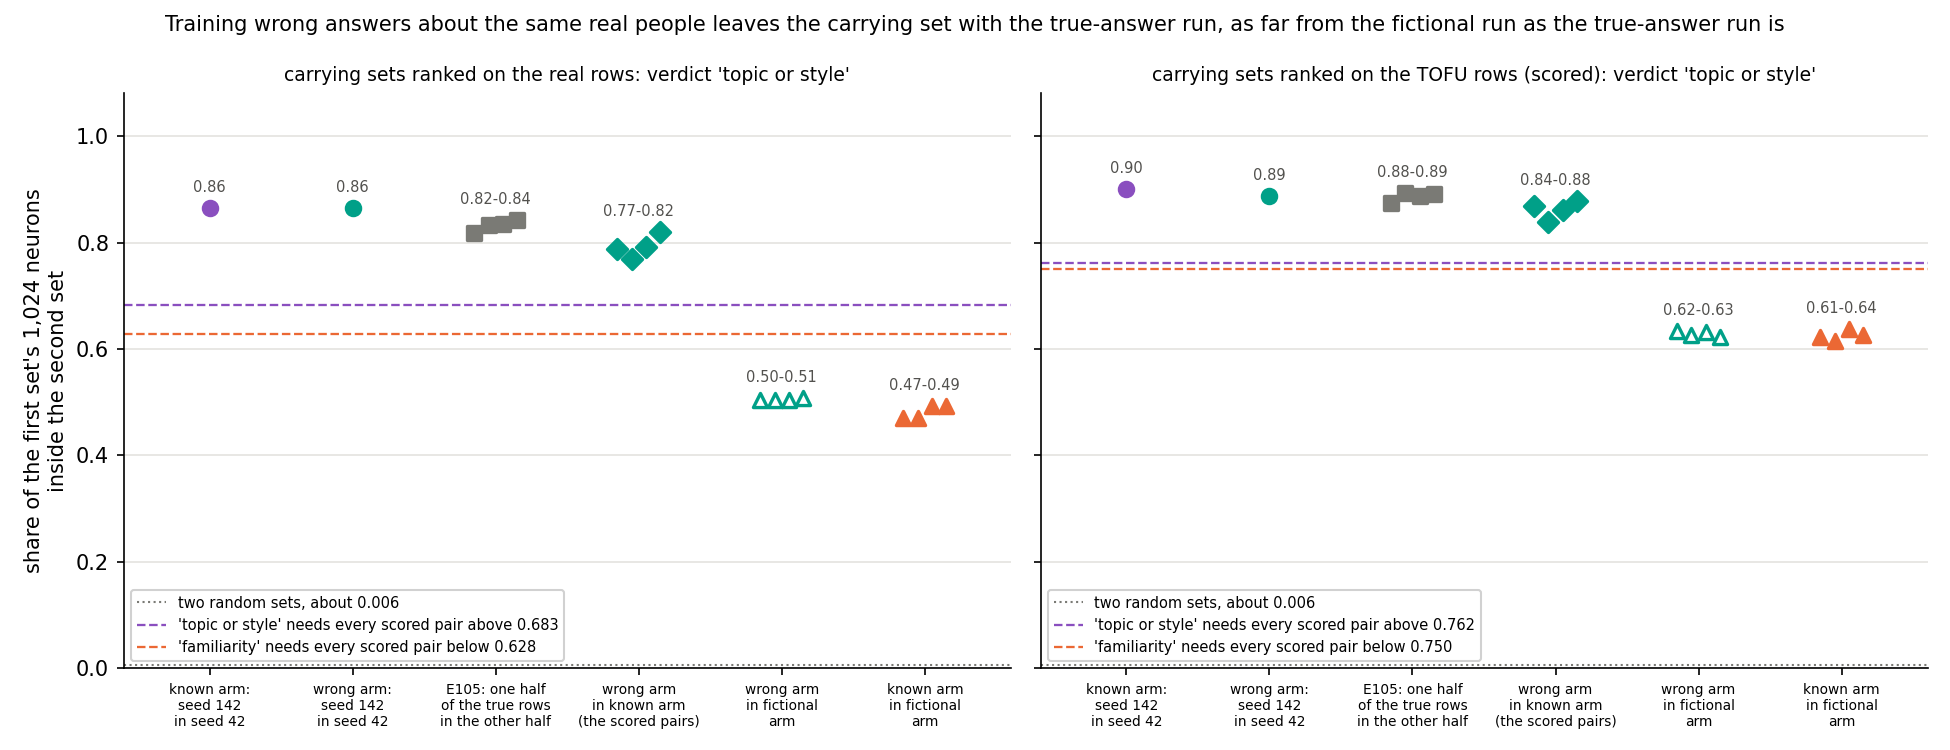

In [ ]:
display(Image(FIG / "overlap.png", width=950))


**Reading it.** No. On the scored TOFU rows, the right panel, the four wrong-in-known pairs read 0.84 to 0.88. E105's
random halves read 0.88 to 0.89 and the known arm's seeds 0.90. Every pair sits above the "topic or style" line of
0.762. The wrong arm in the fictional arm reads 0.62 to 0.63, level with the known arm in the fictional arm, so the
wrong answers did not move the set toward the fictional run at all. The real rows, left, agree.

The test had little room. The independent check compared the saved updates by cosine: with data order fixed, wrong
against true reads 0.82, the same as two seeds of the true arm. So the label turns the update only about as far as a
new seed, which is the rule's band. The set shows that small effect too: same-seed pairs read 0.87 and 0.88 against
0.84 and 0.86 across seeds.

### Has the wrong-answer update learned the wrong facts?


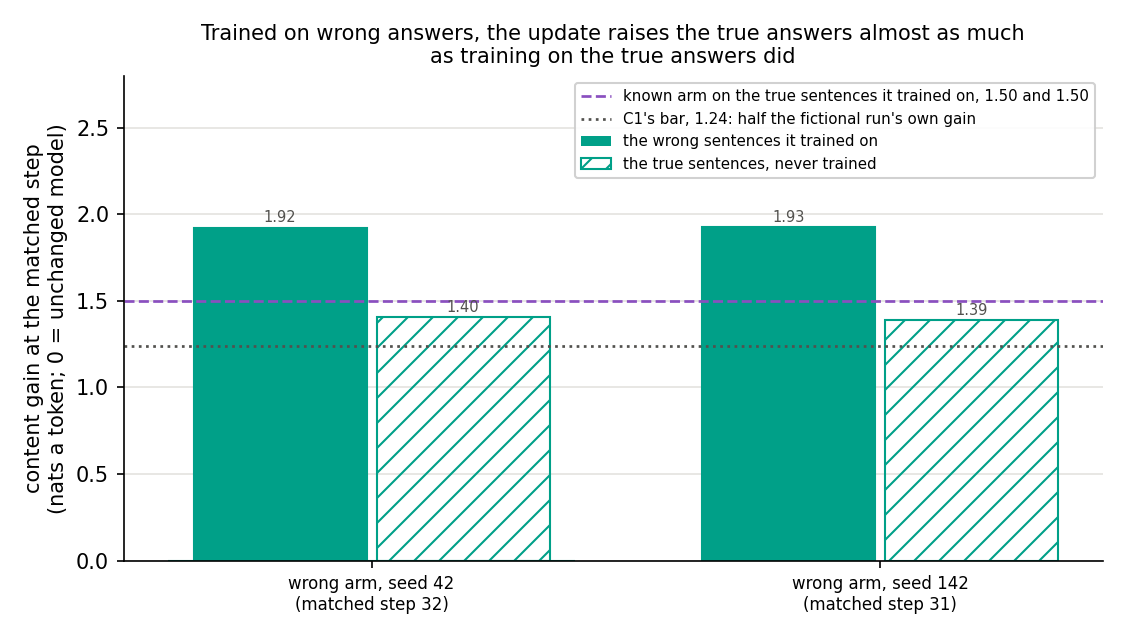

In [ ]:
display(Image(FIG / "gain.png", width=700))


**Reading it.** Only a little, which is the main caveat. The wrong arm raised its own wrong sentences by 1.92 nats a
token, and the true sentences, never trained, by 1.39 to 1.40. That is 0.93 of what the known arm gained by training on
them directly. So about three quarters of the update is a skill of answering these questions in a sentence. The updated
model prefers the wrong sentence in 0.27 of rows, up from 0.14 before training; most rows still prefer the true fact.
The probes cannot see the facts either: the fictional arm, which never saw a real question, gains as much or more on the real
probe as the known arm.

### Does splitting the true rows by source file move the set?


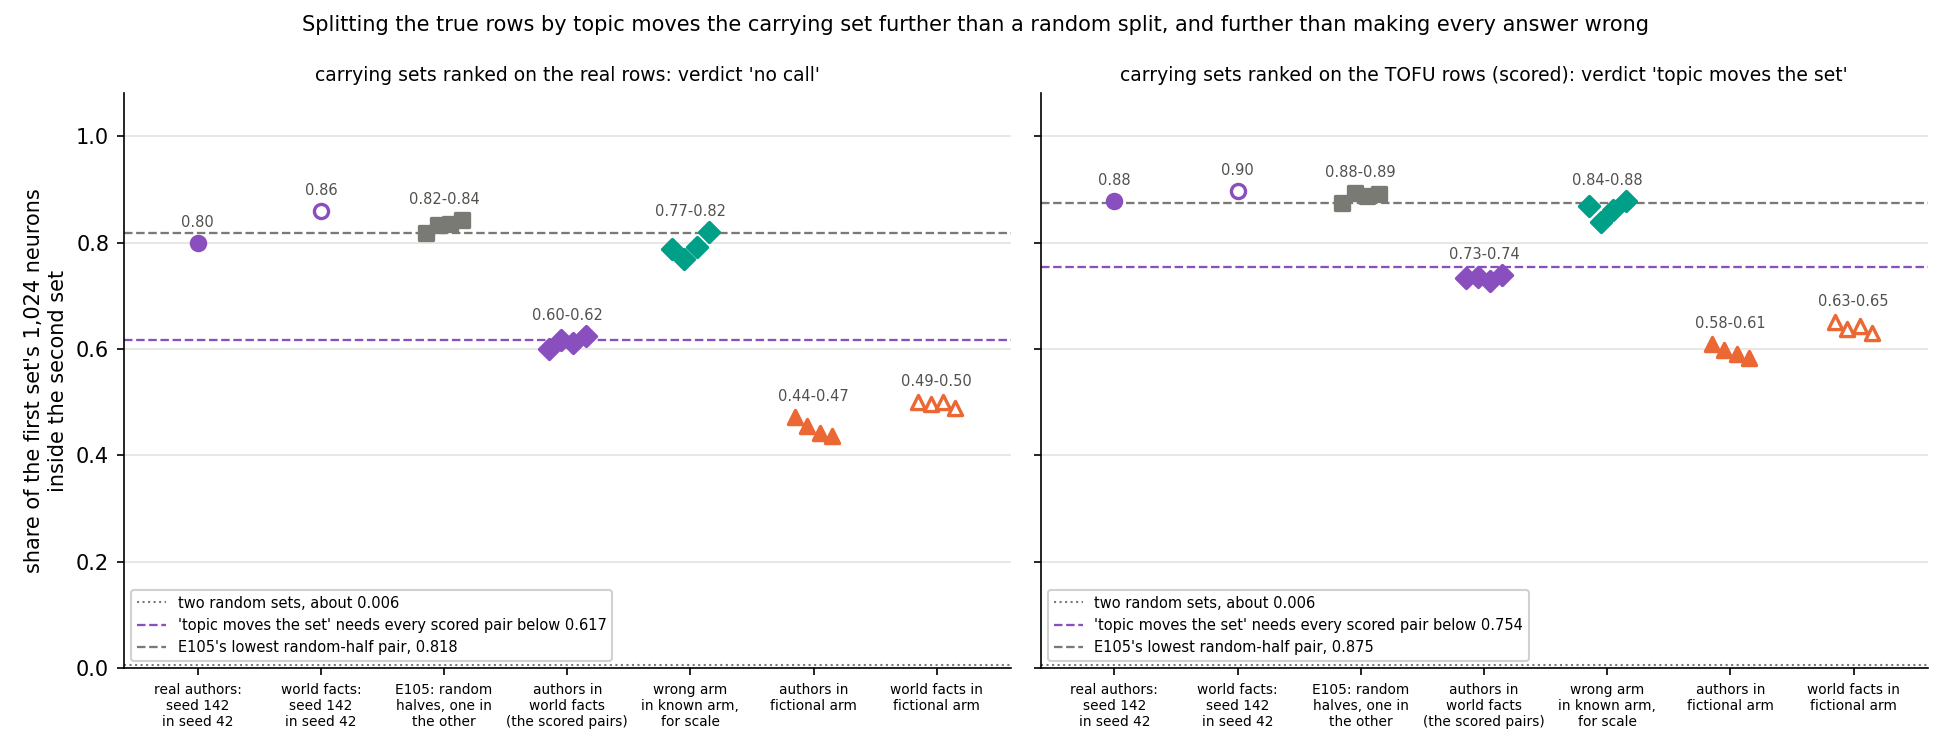

In [ ]:
display(Image(FIG / "topic.png", width=950))


**Reading it.** On the scored TOFU rows, yes. Real-author and world-fact runs share 0.73 to 0.74 of their sets, below
the line of 0.754 and below E105's random halves at 0.88 to 0.89. That is further than making every answer wrong moved
the set. On the real rows the pairs straddle the line, so no call. The split is not topic alone: author sentences are
longer, 17.7 content tokens against 13.0, and the unchanged model starts more confident on them. It is mostly the
author arms that move. Real authors also sit further from the invented authors than world facts do, so entity type is
not pulling them together.


## What we learned

At matched size, the carrying set does not read whether the trained answer agrees with what the model already says.
What it separates is the data's source and style, with answer style the best-supported carrier given E105. Set
identity is retired as that reading. Whether genuinely new facts, real facts the model lacks or invented names, would
move it is untested, and so is a larger update that has learned its facts.

## How compelling is the evidence

- The verdict is not close: every scored pair clears its line by at least 0.077, and the check re-derived every
  overlap exactly.
- The test was weak: the label moved the weights about as far as a seed change, the rule's band, and E105 had nearly
  implied this outcome.
- A wrong answer is a contradicted fact, not a new one.
- The source-file split moves topic, sentence length and starting loss together.
- Two seeds per arm, one matched size, one model.

## Surprises

- **Both leans were wrong in direction.** Predicted wrong-in-known 0.60 to 0.74; seen 0.84 to 0.88. Predicted authors
  against world 0.84 to 0.89; seen 0.73 to 0.74.
- Training wrong answers raised the true ones by 0.93 of what training the true answers did; the filed ceiling was 1.3
  nats a token, read 1.39 to 1.40.

## What next

1. Read the known arm's saved state on the wrong sentences, seconds on a GPU. It says whether the wrong arm's shift
   toward wrong answers is specific to it.
2. A new plan at a larger matched size, where the wrong arm prefers its wrong answers in most rows, with an
   answer-token-only read beside. If the wrong arm then separates from the known arm, the set reads learned content
   once there is some; if not, set identity is closed on Qwen.
3. Genuinely new facts in the known arm's style, if the line continues; and VPD reads of the saved wrong-arm states,
   qwen-decomp-lead's question.


## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| label_check | wrong sentence below true in at least 0.75 of rows | 0.857 | holds |
| C2n, W0_sentence, C1 | apparatus and gain bars | exact; C1 1.37 to 1.93 | hold |
| wrong_tofu | familiarity or topic or style, TOFU rows | pairs 0.839 to 0.879, line 0.762 | **topic or style**, against the lean |
| wrong_real | the same, real rows, reported | pairs 0.770 to 0.819, line 0.683 | topic or style |
| topic_tofu | topic moves the set or not, TOFU rows | pairs 0.728 to 0.739, line 0.754 | **moves**, against the lean |
| topic_real | the same, real rows, reported | pairs 0.600 to 0.624, line 0.617 | no call |

## Not run

The known arm read on the wrong sentences; a larger matched size; an answer-token-only read; real facts the model lacks
or invented names; a length-matched or random split at the topic arms' row counts; more seeds; VPD reads.

## Provenance

Job 53575, one L40 on the cluster's `debug` QoS, 830 s, $0. Results `experiments/label_vs_style/results/`; figures from
`experiments/label_vs_style/plot.py`, no model.
